# Traceable and honest forecasting: live demo
The notebook from the talk *Traceable and honest forecasting across a Bundesliga season* at Machine Learning Week Europe, Munich, 17 Nov 2026. It grades the forecast frozen on 8 October 2026 ([`preregistration/2026-27/`](../preregistration/2026-27/)) against what has happened since, using the newest rolling update in this repo, so the numbers move as the season goes on.

🙋 cells are the audience prompts from the talk. Play along on your own or with a group: fill in your answer (hands per option, or a number), run the cell, then run the reveal below it. Leaving a prompt at `None` is fine: the reveal still works, it just doesn't score you.

Sections: 1 freeze · 2 receipts · 3 black box · 4 the game · 5 honest grading · 6 the reveal · 7 drift, form & what-ifs · 8 rules · 9 the next matchday · 10 your scorecard.

**Appendix:** A1 sensitivity · A2 calibration · A3 reproducibility · A4 crowd · A5 swing matches

In [1]:
# 0 · Setup. The first run downloads free public data and caches it; after that, OFFLINE = True works without a network.
OFFLINE = False
import subprocess, warnings
warnings.filterwarnings('ignore')
import numpy as np, pandas as pd
from glassball import Bundesliga, plots, causal
import reveal, brand, room
brand.apply()   # Wangari chart theme
pd.set_option('display.precision', 3); pd.set_option('display.width', 160)
s = Bundesliga(2026, offline=OFFLINE)
FROZEN = dict(as_of='2026-10-08')   # the information set of the freeze
s

Bundesliga(2026/27: 81/306 matches played, next matchday 10)

## 1 · The freeze is intact

In [2]:
print(subprocess.run(['bash', str(reveal.PRE / 'verify.sh')], capture_output=True, text=True).stdout)
pd.read_csv(reveal.FREEZE / 'table_forecast.csv', index_col=0)[['exp_points', 'p_title', 'p_top4', 'p_relegated']]

All 34 frozen files match MANIFEST.sha256
Fingerprint matches the published hash: e9753a97bafee5a04ce2c9229f843ed216f3e2459d97cd33a45006028530cf1a



,exp_points,p_title,p_top4,p_relegated
Bayern Munich,79.876,8.100e-01,0.996,0.000e+00
Dortmund,68.926,1.421e-01,0.902,0.000e+00
Leverkusen,60.591,2.610e-02,0.631,1.000e-04
RB Leipzig,55.317,8.100e-03,0.374,1.600e-03
Stuttgart,53.992,4.300e-03,0.314,3.100e-03
Freiburg,52.281,3.900e-03,0.238,4.400e-03
Mainz,48.415,1.200e-03,0.128,1.230e-02
Ein Frankfurt,46.899,9.000e-04,0.092,2.270e-02
Augsburg,45.047,4.000e-04,0.067,3.130e-02
Hoffenheim,44.460,3.000e-04,0.061,3.960e-02


### 🙋 Your turn: is 81% too confident?
> **Bayern at 81% for the title, after four matchdays. Too high, about right, or too low?**

Hands for each option. We come back to it in section 6.

In [3]:
room.vote('bayern_81', 'Bayern at 81%: too high, about right or too low?',
          too_high=None, about_right=None, too_low=None)   # <- hands

[bayern_81] no hands entered yet: fill in the counts and re-run


## 2 · Every forecast has a receipt

### 🙋 Your turn: expected goals
> **Bayern at home to RB Leipzig. How many goals should Bayern expect to score?**

Take the room's consensus (or the most common shout). Follow-up: *what would you need to know to answer?*

In [4]:
room.guess('bayern_goals', None, 'Expected Bayern goals vs Leipzig')   # <- e.g. 2.5

[bayern_goals] the room says: None


Answer: 2.95. Room said: None. (no room answer recorded)
Base × home advantage × Bayern attack × Leipzig defence. Within 0.25 counts as right.


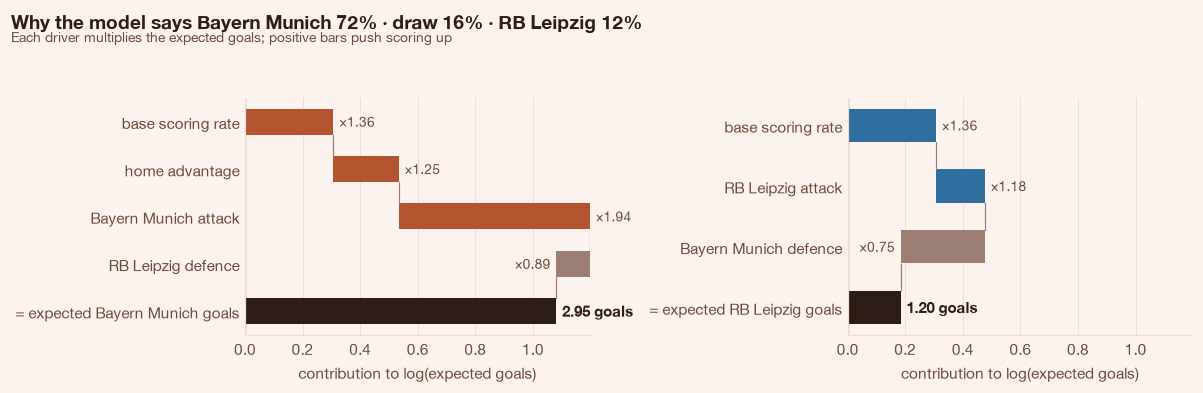

In [5]:
ex = s.explain('bayern', 'leipzig', **FROZEN)
lam = ex.attrs['lambda_home']
room.truth('bayern_goals', round(lam, 2), 'Base × home advantage × Bayern attack × Leipzig defence. '
           'Within 0.25 counts as right.', tolerance=0.25)
plots.explain(ex);

### 🙋 Live: name any match
Take a request. **Before running, ask: which factor will dominate?** (attack, defence or home advantage, and whose)

Dortmund 32% · draw 24% · Bayern Munich 44%
Dominant factor: Bayern Munich attack (×1.97 on away goals)


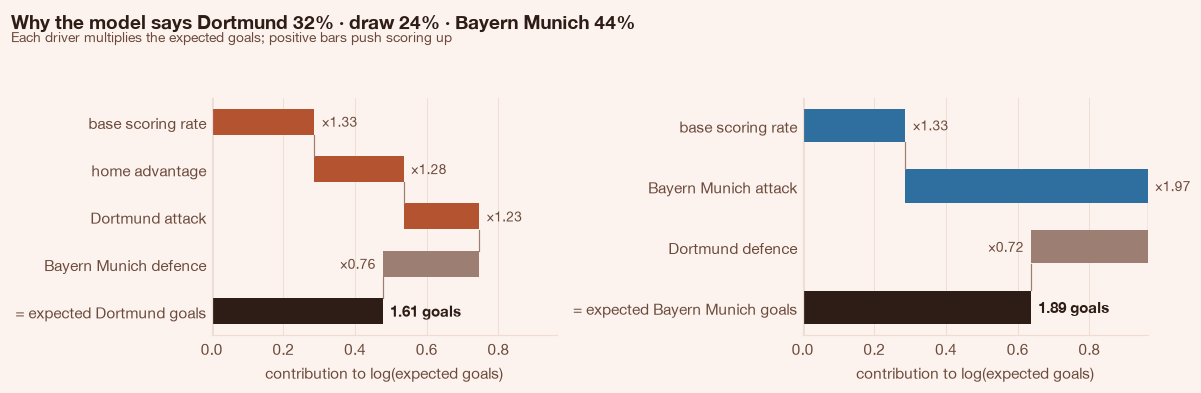

In [6]:
HOME, AWAY = 'bvb', 'bayern'   # <- audience request
ROOM_SAYS = None              # <- e.g. 'bayern attack'
ex = s.explain(HOME, AWAY)
M = ex.attrs['matrix']
print(f"{ex.attrs['home']} {np.tril(M,-1).sum():.0%} · draw {np.trace(M):.0%} · {ex.attrs['away']} {np.triu(M,1).sum():.0%}")
d = ex[ex.driver != 'base scoring rate'].assign(size=lambda x: x.value.abs()).sort_values('size', ascending=False)
top = d.iloc[0]
print(f"Dominant factor: {top.driver} (×{top.multiplier:.2f} on {top.affects})")
if ROOM_SAYS:
    print('The room was right ✓' if all(w in top.driver.lower() for w in ROOM_SAYS.lower().split()) else 'Not this time.')
plots.explain(ex);

## 3 · The black box disagrees

In [7]:
c = s.predict(10, contrast=True)
c[['HomeTeam','AwayTeam','pH','ml_pH','pD','ml_pD','pA','ml_pA']]

,HomeTeam,AwayTeam,pH,ml_pH,pD,ml_pD,pA,ml_pA
0,Bayern Munich,FC Koln,0.867,0.695,0.089,0.202,0.044,0.103
1,Ein Frankfurt,Hoffenheim,0.468,0.418,0.225,0.323,0.307,0.259
2,Elversberg,Freiburg,0.366,0.318,0.244,0.289,0.390,0.392
3,Leverkusen,Paderborn,0.689,0.724,0.198,0.181,0.113,0.095
4,M'gladbach,Dortmund,0.212,0.215,0.245,0.235,0.542,0.551
5,Union Berlin,RB Leipzig,0.229,0.207,0.245,0.255,0.526,0.538
6,Schalke 04,Stuttgart,0.201,0.235,0.271,0.147,0.529,0.618
7,Augsburg,Mainz,0.419,0.385,0.255,0.274,0.325,0.341
8,Werder Bremen,Hamburg,0.495,0.449,0.262,0.312,0.243,0.239


### 🙋 Your turn: who do you trust?
> **Bayern at home: the glass box says 78–88%, the GBM 60–72%. Who do you trust?**

Hands for each. Resolved in section 6 with Bayern's actual home results since the freeze.

In [8]:
room.vote('bayern_home', 'Bayern at home: glass box or GBM?', glass_box=None, gbm=None)   # <- hands

[bayern_home] no hands entered yet: fill in the counts and re-run


## 4 · The game: the room vs the model vs the bookmakers
Share of raised hands per match (0–100), shaded a little toward 50: a hand is a pick, not a probability.

In [9]:
CROWD = [None, None, None, None, None]   # <- e.g. [62, 40, 58, 35, 50]
g = pd.read_csv('mystery_matches.csv')
g[['season','matchday','home','home_pos','away','away_pos']]

,season,matchday,home,home_pos,away,away_pos
0,2021/22,26,Ein Frankfurt,10,Bochum,11
1,2024/25,31,Wolfsburg,12,Freiburg,5
2,2019/20,11,M'gladbach,1,Werder Bremen,13
3,2022/23,15,M'gladbach,9,Dortmund,6
4,2024/25,33,Union Berlin,13,Heidenheim,16


In [10]:
y = g.home_won.to_numpy()
rows = {'Model': g.model_pH, 'Bookmakers': g.book_pH, 'Coin flip': np.full(5, 0.5)}
if all(v is not None for v in CROWD):
    rows = {'The room': np.array(CROWD) / 100, **rows}
res = pd.DataFrame({k: ((np.asarray(v) - y) ** 2).mean() for k, v in rows.items()}, index=['Brier']).T.sort_values('Brier')
if 'The room' in res.index:
    room.ROOM['game'] = {'question': 'Did the room beat the model on the 5 matches?', 'room_answer': f"Brier {res.loc['The room','Brier']:.3f}",
                         'truth': f"model {res.loc['Model','Brier']:.3f}", 'right': res.loc['The room','Brier'] < res.loc['Model','Brier']}
display(g[['home','away','score','model_pH','book_pH']].assign(room=[None if c is None else c/100 for c in CROWD]))
res.style.format('{:.3f}').bar(color='#E8A487')

,home,away,score,model_pH,book_pH,room
0,Ein Frankfurt,Bochum,2-1,0.576,0.601,None
1,Wolfsburg,Freiburg,0-1,0.452,0.404,None
2,M'gladbach,Werder Bremen,3-1,0.520,0.485,None
3,M'gladbach,Dortmund,4-2,0.350,0.289,None
4,Union Berlin,Heidenheim,0-3,0.433,0.471,None


,Brier
Model,0.245
Coin flip,0.250
Bookmakers,0.263


## 5 · Honest grading

### 🙋 Your turn: the forecaster duel
> **Favourites win 65% of the time. A says 90% for every favourite, B says 65%. Who's better?**

Hands for A, then B. Both pick the favourite every time, so their accuracy is identical.

In [11]:
room.vote('forecasters', 'Who is the better forecaster?', A=None, B=None)   # <- hands

[forecasters] no hands entered yet: fill in the counts and re-run


In [12]:
rng = np.random.default_rng(17)
won = rng.random(1000) < 0.65                     # 1,000 matches, favourites win 65%
duel = pd.DataFrame({f: {'accuracy': won.mean(), 'Brier': ((p - won) ** 2).mean()}
                     for f, p in {'A (says 90%)': 0.90, 'B (says 65%)': 0.65}.items()}).T
display(duel.style.format({'accuracy': '{:.1%}', 'Brier': '{:.3f}'}))
room.truth('forecasters', 'B', 'Same picks, same accuracy. B tells the truth; a proper score sees it, accuracy cannot.')

,accuracy,Brier
A (says 90%),66.6%,0.277
B (says 65%),66.6%,0.223


Answer: B. Room said: None. (no room answer recorded)
Same picks, same accuracy. B tells the truth; a proper score sees it, accuracy cannot.


### 🙋 Your turn: did I beat the bookies?
> **Seven seasons, every match predicted blind. In how many did my model beat the bookmakers?**

Hands for 0, 1–3, 4–6, 7.

In [13]:
room.vote('bookies', 'Seasons the model beat the bookmakers', zero=None, one_to_three=None, four_to_six=None, seven=None)   # <- hands

[bookies] no hands entered yet: fill in the counts and re-run


In [14]:
from glassball.model import outcome_index, rps
wf = pd.read_csv(reveal.PRE / 'figures' / 'data' / 'walkforward_2019_2025.csv')
o = outcome_index(wf.FTHG.values, wf.FTAG.values)
per = wf.assign(o=o).groupby('Season').apply(lambda d: pd.Series({
    'glass box': rps(d[['pH','pD','pA']].values, d.o.values).mean(),
    'bookmakers': rps(d[['book_pH','book_pD','book_pA']].values, d.o.values).mean()}))
wins = int((per['glass box'] < per['bookmakers']).sum())
bucket = 'zero' if wins == 0 else 'one_to_three' if wins <= 3 else 'four_to_six' if wins <= 6 else 'seven'
display(per.style.format('{:.4f}'))
room.truth('bookies', bucket, f'The model beat the bookmakers in {wins} of 7 seasons.')

,glass box,bookmakers
Season,,
2019,0.2084,0.2042
2020,0.2041,0.1967
2021,0.2070,0.2025
2022,0.2063,0.2041
2023,0.1943,0.1847
2024,0.2091,0.2016
2025,0.1969,0.1901


Answer: 0. Room said: None. (no room answer recorded)
The model beat the bookmakers in 0 of 7 seasons.


## 6 · The reveal: the frozen forecast, graded
From the automatic rolling updates (`git pull` first).

### 🙋 Your turn: place your bets
> **Since the freeze: did the glass box beat (1) the GBM, (2) the bookmakers, (3) plain league averages?**

Count the room once, then hands for each statement you believe.

In [15]:
ROOM_SIZE = None                                                 # <- people in the room
BETS = {'beat_gbm': None, 'beat_bookies': None, 'beat_base': None}   # <- hands for each statement

In [16]:
subprocess.run(['git', '-C', str(reveal.REPO), 'pull', '--quiet'], capture_output=True)   # latest rolling update; harmless if offline
reveal.show_scoreboard(BETS, ROOM_SIZE)

Forecaster,RPS,Accuracy,RPS gap
Glass box,0.197,58%,
GBM,0.206,56%,+0.009 · noise
Bookmakers,0.204,62%,+0.007 · noise
Base rates,0.229,49%,+0.032


In [17]:
reveal.show_calls()

In [18]:
reveal.show_bayern()     # resolves 'who do you trust?' from section 3

,Match,Score,Glass box,GBM,Closer
MD6,Bayern – RB Leipzig,6–1,72%,67%,glass box
MD8,Bayern – Dortmund,2–2,62%,45%,GBM


Title,8 Oct,After MD9,Change
Bayern Munich,81%,87%,▲ 6
Dortmund,14%,9%,▼ 5
Leverkusen,3%,1%,▼ 2
Relegation,8 Oct,After MD9,Change
Schalke 04,31%,54%,▲ 23
M'gladbach,25%,37%,▲ 12
Union Berlin,33%,31%,▼ 2
Paderborn,37%,28%,▼ 9
RB Leipzig,37%,68%,▲ 31


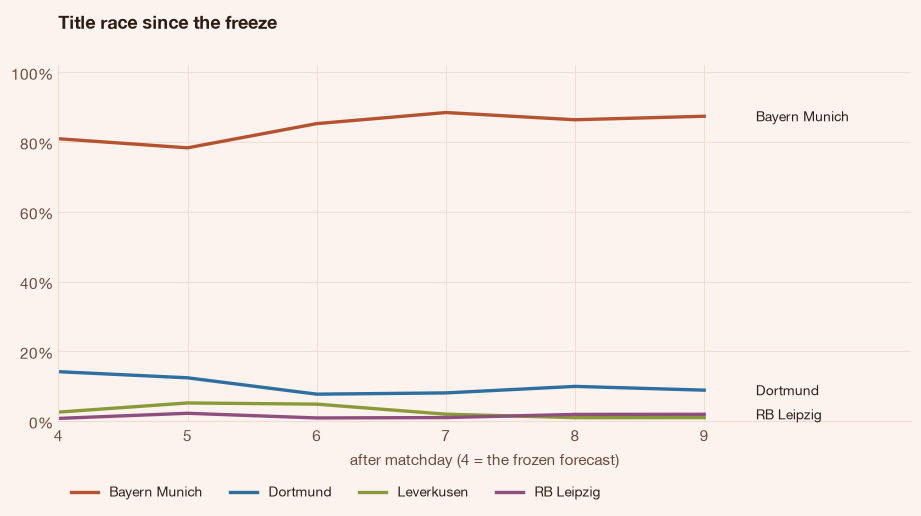

In [19]:
reveal.show_season()     # resolves 'is 81% too confident?' from section 1
reveal.drift_figure();

## 7 · Drift, form and what-ifs

### 🙋 Your turn: how fast should it change its mind?
> **2023/24, Leverkusen unbeaten: before which matchday did the model first make them title favourites?**

Take the most common shout. Within 2 matchdays counts.

In [20]:
room.guess('leverkusen_md', None, 'Matchday Leverkusen became favourites')   # <- e.g. 10

[leverkusen_md] the room says: None


In [21]:
race = pd.read_csv(reveal.PRE / 'figures' / 'data' / 'title_race_2023.csv', index_col=0)
first = int(race.index[race['Leverkusen'] > 0.5][0])
room.truth('leverkusen_md', first, f'Leverkusen first passed 50% in the forecast made before matchday {first}.', tolerance=2)

Answer: 19. Room said: None. (no room answer recorded)
Leverkusen first passed 50% in the forecast made before matchday 19.


### 🙋 Your turn: is form real?
> **A team has beaten expectations three games running. Will it beat them again next game?**

Hands for A (yes, momentum), B (a little), C (no more than usual).

In [22]:
room.vote('form', 'Is form real?', A=None, B=None, C=None)   # <- hands

[form] no hands entered yet: fill in the counts and re-run


naive slope +0.070 ± 0.006   adjusted -0.000 ± 0.007
Answer: C. Room said: None. (no room answer recorded)
Hot teams next game: 1.36 points vs 1.38 expected.


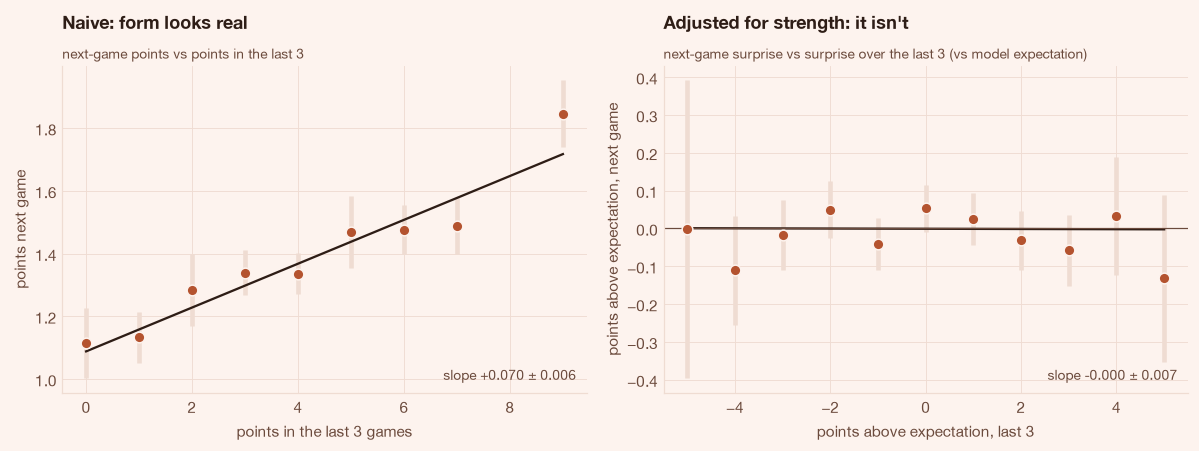

In [23]:
m = causal.momentum(offline=OFFLINE)
print(f"naive slope {m['naive_slope']:+.3f} ± {m['naive_se']:.3f}   adjusted {m['adjusted_slope']:+.3f} ± {m['adjusted_se']:.3f}")
room.truth('form', 'C', f"Hot teams next game: {m['hot_next_points']:.2f} points vs {m['hot_next_expected']:.2f} expected.")
plots.form(m);

### 🙋 Live what-if: give me an injury or a transfer
A big star out ≈ attack −0.15; a key defender out ≈ defence +0.05 to +0.1; a strong signing ≈ attack +0.1.

In [24]:
TEAM, FIELD, SHIFT = 'bayern', 'attack', -0.15   # <- audience request
base = s.forecast(n_sims=10_000).table
hurt = s.forecast(n_sims=10_000, shift={TEAM: {FIELD: SHIFT}}).table
t = s.team(TEAM)
cmp = pd.DataFrame({'as forecast': base.loc[t, ['p_title','p_top4','p_relegated','exp_points']],
                    f'{FIELD} {SHIFT:+}': hurt.loc[t, ['p_title','p_top4','p_relegated','exp_points']]})
cmp

,as forecast,attack -0.15
p_title,0.873,0.747
p_top4,0.999,0.992
p_relegated,0.000,0.000
exp_points,80.083,76.329


## 8 · The four rules: what does your team do today?
Hands per rule; no right answer, but a great conversation starter afterwards.

In [25]:
room.vote('rules', 'Which rules does your team follow today?',
          receipts=None, honest_grading=None, freeze_and_fingerprint=None, drift_vs_edits=None)   # <- hands

[rules] no hands entered yet: fill in the counts and re-run


## 9 · The next matchday
The model's probabilities for the next matchday, from the same frozen code. Write yours down before kick-off and grade both afterwards.

In [26]:
nxt = s.predict()[['Kickoff','HomeTeam','AwayTeam','pH','pD','pA']]
nxt.to_csv('next_matchday_forecast.csv', index=False)
nxt

,Kickoff,HomeTeam,AwayTeam,pH,pD,pA
0,2026-11-20 20:30:00,Bayern Munich,FC Koln,0.867,0.089,0.044
1,2026-11-21 15:30:00,Ein Frankfurt,Hoffenheim,0.468,0.225,0.307
2,2026-11-21 15:30:00,Elversberg,Freiburg,0.366,0.244,0.390
3,2026-11-21 15:30:00,Leverkusen,Paderborn,0.689,0.198,0.113
4,2026-11-21 15:30:00,M'gladbach,Dortmund,0.212,0.245,0.542
5,2026-11-21 15:30:00,Union Berlin,RB Leipzig,0.229,0.245,0.526
6,2026-11-21 18:30:00,Schalke 04,Stuttgart,0.201,0.271,0.529
7,2026-11-22 15:30:00,Augsburg,Mainz,0.419,0.255,0.325
8,2026-11-22 17:30:00,Werder Bremen,Hamburg,0.495,0.262,0.243


## 10 · How did you do?
Every 🙋 answer you filled in, against the truth.

In [27]:
room.scorecard()

No graded answers yet.


,question,room said,answer,right?
0,"Bayern at 81%: too high, about right or too low?",None,too low,
1,Expected Bayern goals vs Leipzig,None,2.95,
2,Bayern at home: glass box or GBM?,None,GBM,
3,Who is the better forecaster?,None,B,
4,Seasons the model beat the bookmakers,None,0,
5,beat_gbm,None,yes,
6,beat_bookies,None,yes,
7,beat_base,None,yes,
8,Matchday Leverkusen became favourites,None,19,
9,Is form real?,None,C,


---
# Appendix: cut from the main flow
Use when a question calls for it. Each part runs on its own after section 0.

## A1 · How fragile is a single forecast?

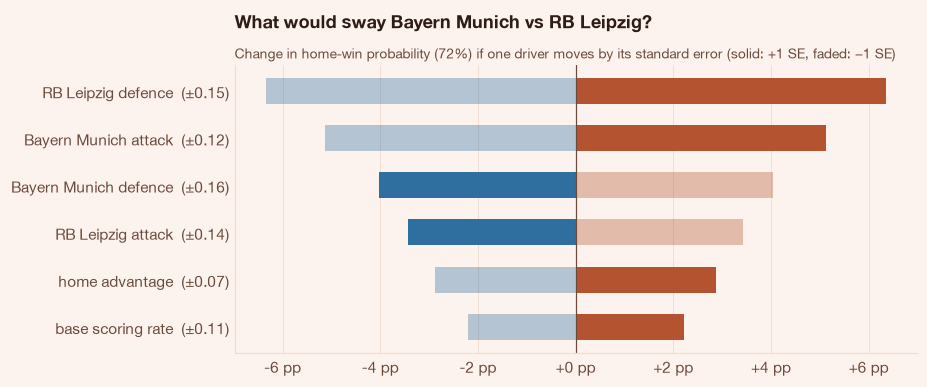

In [28]:
ex = s.explain('bayern', 'leipzig', **FROZEN)
plots.sensitivity(ex);

## A2 · Calibration

### 🙋 Your turn: is the average calibrated?
> **Is a model that always predicts the league's average result calibrated?**

Hands for yes, then no.

In [29]:
room.vote('average_calibrated', 'Always predicting the average: calibrated?', yes=None, no=None)   # <- hands


[average_calibrated] no hands entered yet: fill in the counts and re-run


Always say: home 43%, draw 25%, away 32%.  It happens: home 43%, draw 25%, away 32%.
RPS: always-average 0.2316 vs glass box 0.2037
Answer: yes. Room said: None. (no room answer recorded)
Perfectly calibrated, and useless: calibration needs sharpness to be worth anything.


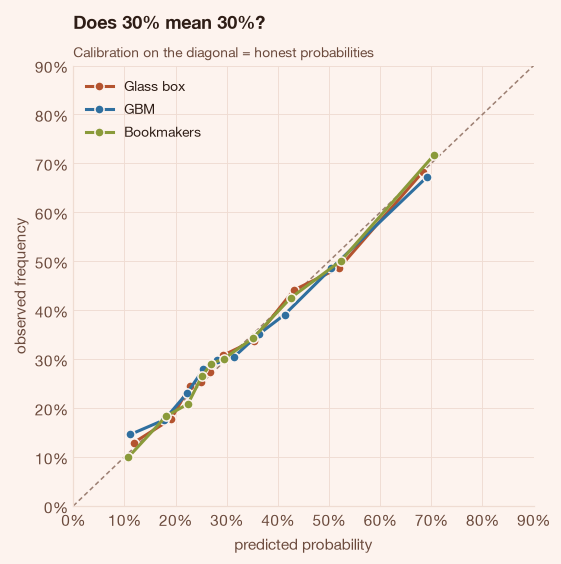

In [30]:
from glassball.model import outcome_index, rps
wf = pd.read_csv(reveal.PRE / 'figures' / 'data' / 'walkforward_2019_2025.csv')
o = outcome_index(wf.FTHG.values, wf.FTAG.values)
avg = np.bincount(o, minlength=3) / len(o)
print(f'Always say: home {avg[0]:.0%}, draw {avg[1]:.0%}, away {avg[2]:.0%}.  It happens: home {avg[0]:.0%}, draw {avg[1]:.0%}, away {avg[2]:.0%}.')
print(f'RPS: always-average {rps(np.tile(avg, (len(o), 1)), o).mean():.4f} vs glass box {rps(wf[["pH","pD","pA"]].values, o).mean():.4f}')
room.truth('average_calibrated', 'yes', 'Perfectly calibrated, and useless: calibration needs sharpness to be worth anything.')
P = {'Glass box': wf[['pH','pD','pA']].values, 'GBM': wf[['ml_pH','ml_pD','ml_pA']].values, 'Bookmakers': wf[['book_pH','book_pD','book_pA']].values}
plots.reliability(P, o);

## A3 · Reproducibility

### 🙋 Your turn: reproducibility
> **Same data, same code, same seed, older Python libraries. How far does the black box move?**

Hands for A (not at all), B (under 1 point), C (about 5 points), D (over 20).

In [31]:
room.vote('repro', 'How far does the black box move?', A=None, B=None, C=None, D=None)   # <- hands


[repro] no hands entered yet: fill in the counts and re-run


In [32]:
room.truth('repro', 'C', 'Up to 5.3 percentage points (1.6 on average) on matchday 5, Python 3.10 + scikit-learn 1.7.2 '
           'vs the frozen 3.14 + 1.9.1. The glass box matched to the 4th decimal.')

Answer: C. Room said: None. (no room answer recorded)
Up to 5.3 percentage points (1.6 on average) on matchday 5, Python 3.10 + scikit-learn 1.7.2 vs the frozen 3.14 + 1.9.1. The glass box matched to the 4th decimal.


## A4 · The crowd (natural experiment)

### 🙋 Your turn: how much is the crowd worth?
> **In 2020–21 the stadiums were empty. How much of home advantage disappeared?**

Hands for none, ~25%, ~40%, ~75%, all.

In [33]:
room.vote('crowd', 'Share of home advantage that disappeared', none=None, q25=None, q40=None, q75=None, all=None)   # <- hands

[crowd] no hands entered yet: fill in the counts and re-run


Answer: ~40%. Room said: None. (no room answer recorded)
About 42% (95% CI includes zero: suggestive). Mechanism: the away teams' card disadvantage nearly vanished.


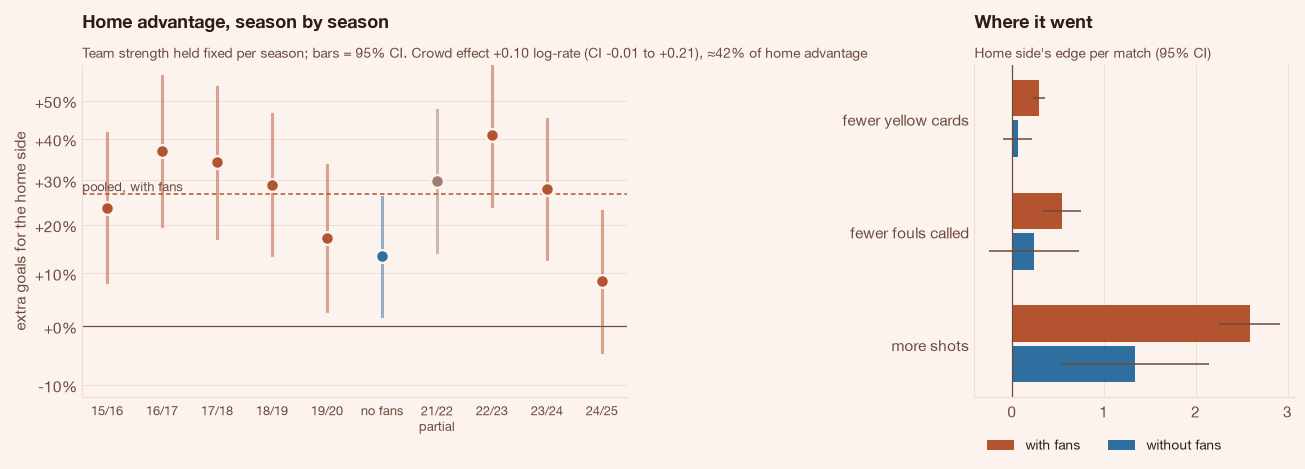

In [34]:
cr = causal.crowd_effect(offline=OFFLINE)
share = cr['crowd_share']
nearest = min({'none': 0, 'q25': .25, 'q40': .40, 'q75': .75, 'all': 1}.items(), key=lambda kv: abs(kv[1] - share))[0]
room.truth('crowd', nearest, f"About {share:.0%} (95% CI includes zero: suggestive). Mechanism: the away teams' card disadvantage nearly vanished.")
plots.crowd(cr);

## A5 · Which matches decide the title?

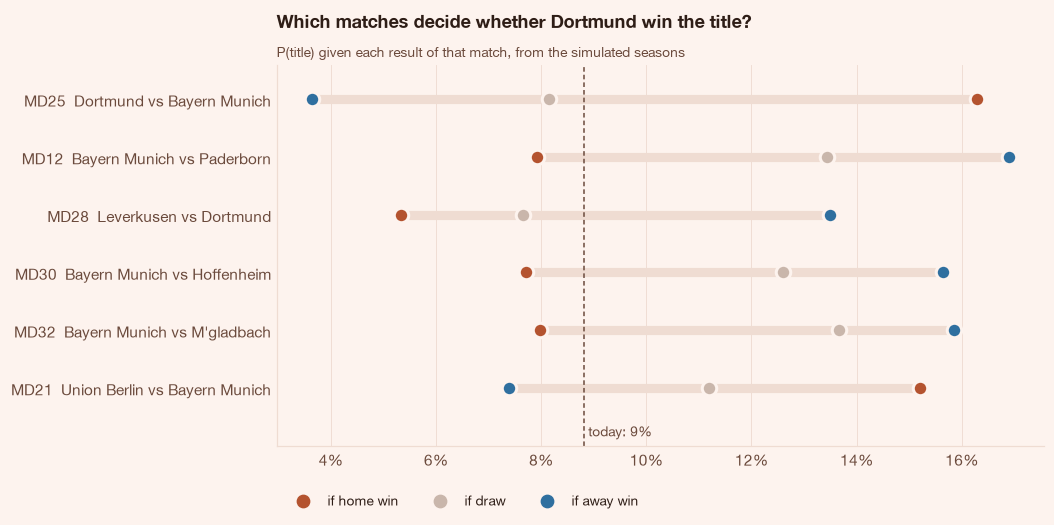

In [35]:
fc = s.forecast(n_sims=10_000)
plots.swing(fc.swing('bvb', 'title', top=6));